In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


%matplotlib inline

In [2]:
train = pd.read_csv("train.csv")
econ = pd.read_csv("economic_indicators.csv")

In [3]:
train.columns = train.columns.str.lower().str.replace(" ", "_")

train_categorical = ["id", "country_id", "loan_type", "new_versus_repeat"]
train_dates = ["disbursement_date", "due_date"] # yyyy-mm-dd
train_numerical = ["customer_id", "tbl_loan_id", "lender_id", "total_amount", "total_amount_to_repay", "duration",
                   "amount_funded_by_lender", "lender_portion_funded", "lender_portion_to_be_repaid"]

#deal with categorical
for cat in train_categorical:
    train[cat] = train[cat].str.lower().str.replace(" ", "_")

# deal with dates
for date in train_dates:
    train[date] = pd.to_datetime(train[date])

#deal with numerical


In [5]:
econ.columns = econ.columns.str.lower().str.replace(" ", "_")

econ_categorical = ["country", "indicator"]

# deal with categorical
for cat in econ_categorical:
    econ[cat] = econ[cat].str.lower().str.replace(" ", "_")

In [10]:
# train.isnull().sum() # No null entries
# train.duplicated().sum() # exact duplicates = 0

# Handling Outliers: use np.log1p()
# train["duration_log"] = np.log1p(train["duration"])
# train["total_amount_log"] = np.log1p(train['total_amount'])

In [9]:
# Explore the data
# Univariate analysis of loan amounts, durations and the target; 
# bivariate analysis of loan type, new versus repeat and amount against the target;
# multivariate views with correlation matrices and grouped statistics, using histograms, box plots, count plots, heatmaps and scatter plots.

# →
# How do loan amounts and durations distribute, and do defaulters differ?
# →
# Do repeat customers default more or less than new ones?
# →
# Which loan types carry the highest default rate?
# 4
# **************************************************************
# Explore the structure and patterns within the dataset.

# Possible analysis areas:

# Univariate Analysis
# -----------------------------
# Distribution of loan amounts
# Loan duration patterns
# Target imbalance

# Bivariate Analysis
# ---------------------
# Loan type vs target
# Repeat customers vs target
# Loan amount vs target
    
# Multivariate Analysis
# ------------------------------
# Feature relationships
# Correlation analysis
# Grouped statistics
# Possible visualizations:

# Histograms
# Boxplots
# Countplots
# Heatmaps
# Scatterplots

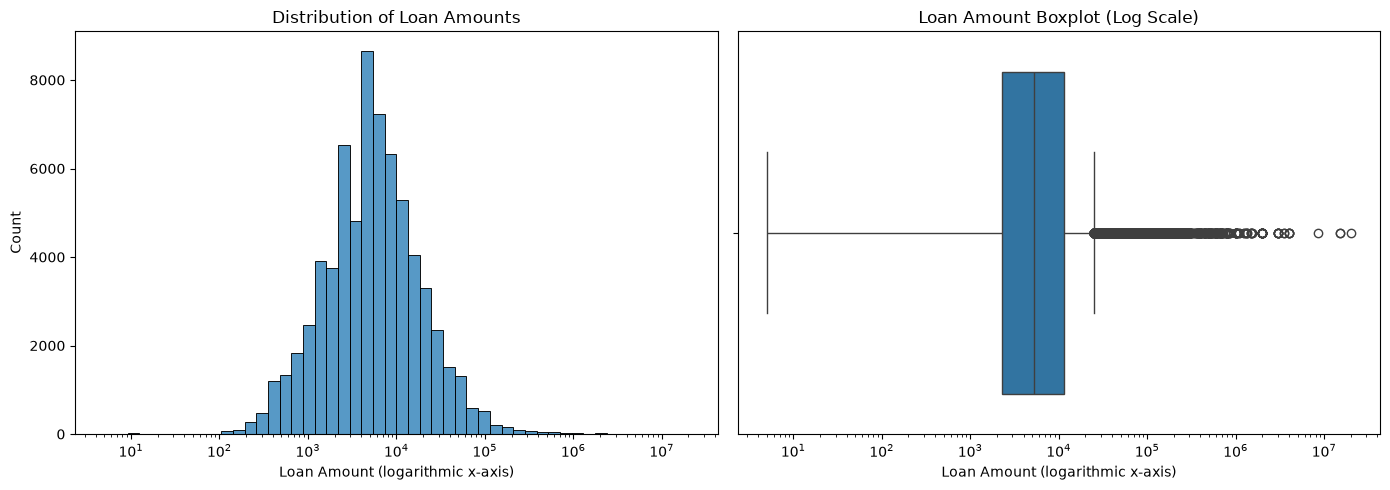

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.histplot(
    data=train, x="total_amount",
    bins=50, log_scale=(True, False),
    ax=axes[0]
)
axes[0].set_title("Distribution of Loan Amounts")
axes[0].set_xlabel("Loan Amount (logarithmic x-axis)")

sns.boxplot(data=train, x="total_amount", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Loan Amount Boxplot (Log Scale)")
axes[1].set_xlabel("Loan Amount (logarithmic x-axis)")

plt.tight_layout()
plt.show()

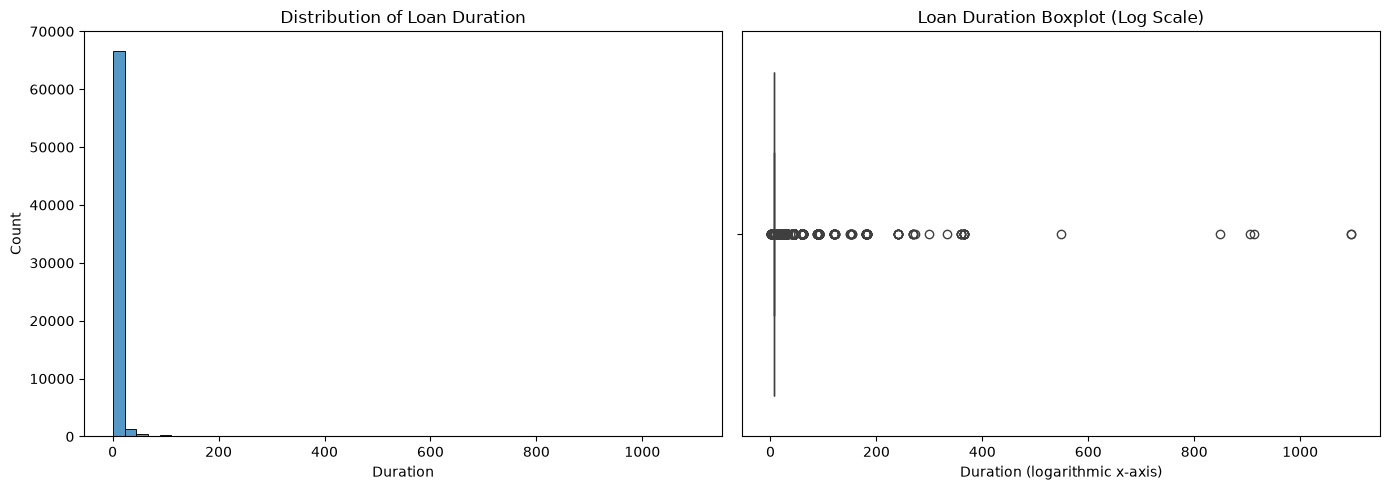

Most common durations:


duration
7     65030
14     1537
30      953
90      237
60      198
45      113
31       73
29       65
25       36
27       31
Name: count, dtype: int64

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=train, x="duration", bins=50, ax=axes[0])
axes[0].set_title("Distribution of Loan Duration")
axes[0].set_xlabel("Duration")

sns.boxplot(data=train, x="duration", ax=axes[1])
# axes[1].set_xscale("log")
axes[1].set_title("Loan Duration Boxplot (Log Scale)")
axes[1].set_xlabel("Duration (logarithmic x-axis)")

plt.tight_layout()
plt.show()

print("Most common durations:")
display(train["duration"].value_counts().head(10))

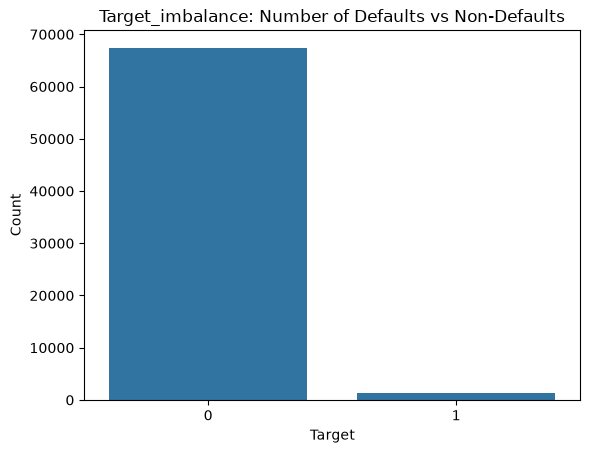

target
0    0.981676
1    0.018324
Name: proportion, dtype: float64

In [29]:
sns.countplot(data=train, x="target")
plt.title("Target_imbalance: Number of Defaults vs Non-Defaults")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()
display(train['target'].value_counts(normalize=True))

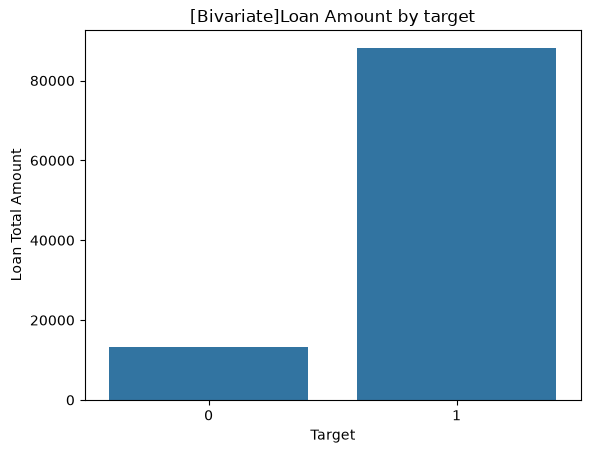

In [49]:
sns.barplot(data=train, x="target", y="total_amount", errorbar=None)
plt.title("[Bivariate]Loan Amount by target")
plt.xlabel("Target")
plt.ylabel("Loan Total Amount")
plt.show()

In [62]:
train.groupby("target")["loan_type"].value_counts() #Loan type vs target

target  loan_type
0       type_1       61273
        type_7        2524
        type_5        1395
        type_4        1062
        type_9         462
        type_6         316
        type_2         220
        type_10         42
        type_15         36
        type_14         20
        type_11         12
        type_13         10
        type_17          6
        type_21          5
        type_16          4
        type_20          3
        type_18          3
        type_12          2
        type_19          1
1       type_1         550
        type_7         225
        type_4         141
        type_2         140
        type_5         119
        type_6          44
        type_20         15
        type_9          13
        type_17          5
        type_10          3
        type_12          2
        type_21          1
Name: count, dtype: int64

In [65]:
train.groupby("target")["new_versus_repeat"].value_counts() # Repeat customers vs target

target  new_versus_repeat
0       repeat_loan          66962
        new_loan               434
1       repeat_loan           1150
        new_loan               108
Name: count, dtype: int64

In [71]:
numeric_cols = [
    "total_amount",
    "total_amount_to_repay",
    "duration",
    "amount_funded_by_lender",
    "lender_portion_funded",
    "lender_portion_to_be_repaid",
    "target"
]

train[numeric_cols].corr()

,total_amount,total_amount_to_repay,duration,amount_funded_by_lender,lender_portion_funded,lender_portion_to_be_repaid,target
total_amount,1.000000,0.997512,0.466857,0.434888,-0.040187,0.441329,0.075206
total_amount_to_repay,0.997512,1.000000,0.474227,0.410673,-0.037044,0.419561,0.073853
duration,0.466857,0.474227,1.000000,0.354720,-0.020807,0.384117,0.172067
amount_funded_by_lender,0.434888,0.410673,0.354720,1.000000,0.096645,0.997459,0.103777
lender_portion_funded,-0.040187,-0.037044,-0.020807,0.096645,1.000000,0.088441,0.045797
lender_portion_to_be_repaid,0.441329,0.419561,0.384117,0.997459,0.088441,1.000000,0.110728
target,0.075206,0.073853,0.172067,0.103777,0.045797,0.110728,1.000000


In [73]:
from sklearn.metrics import mutual_info_score

def mutual_info_target_score(series):
    return mutual_info_score(series, train.target)

mi = train[train_categorical].apply(mutual_info_target_score)
mi.sort_values(ascending=False)

id                   0.091442
loan_type            0.015103
new_versus_repeat    0.002525
country_id           0.000000
dtype: float64